## Problematica 2

In [ ]:
!pip install pgmpy

### Como se relacionan la distancia y el tiempo de traslado de servicios de urgencia con la gravedad de los siniestros viales en las comunas de la RM?

In [ ]:
import pandas as pd
import geopandas as gpd
import numpy as np
from shapely import wkt
from sklearn.preprocessing import KBinsDiscretizer
from imblearn.over_sampling import SMOTE
from pgmpy.models.BayesianNetwork import BayesianNetwork
from pgmpy.inference import VariableElimination

### Carga de datos (again)

In [ ]:
# Accidentes
df_accidentes = pd.read_csv("accidentes.csv")
df_accidentes["geometry"] = df_accidentes["geometry"].apply(wkt.loads)
gdf_accidentes = gpd.GeoDataFrame(df_accidentes, geometry="geometry", crs="EPSG:32719").to_crs(epsg=4326)

# Rutas
df_rutas = pd.read_csv("rutas.csv")

# Hospitales
df_hospitales = pd.read_csv("hospitales.csv")
df_hospitales["geometry"] = df_hospitales["geometry"].apply(wkt.loads)
gdf_hospitales = gpd.GeoDataFrame(df_hospitales, geometry="geometry", crs="EPSG:3857").to_crs(epsg=4326)

#### Preparamos las variables de la red bayesiana:

In [ ]:
dist_min = df_rutas.groupby("ID")["path_length"].min().reset_index()
dist_min.columns = ["ID", "min_path_length"]

gdf_accidentes = gdf_accidentes.merge(dist_min, how="left", on="ID")

cols_edad = ["EDAD_0A5", "EDAD_6A14", "EDAD_15A64", "EDAD_65YMAS"]
features_bayes = ["estimated_time_minutes", "min_path_length"] + cols_edad

X_bayes = gdf_accidentes[features_bayes].copy()
y_bayes = gdf_accidentes["Gravedad"]

### Veremos el balance de la gravedad para ver si es necesario aplicar SMOTE

In [ ]:
total = len(gdf_accidentes)
for val, count in y_bayes.value_counts().items():
    pct = count / total * 100
    print(f"Gravedad = {val}: {count} casos ({pct:.2f}%)")

Gravedad = 0: 15092 casos (87.75%)
Gravedad = 1: 2106 casos (12.25%)


### Eliminamos NaN (requerido para aplicar SMOTE)

In [ ]:
# 🚦 5️⃣ Eliminar filas con NaN (requerido para SMOTE)
Xy_bayes = pd.concat([X_bayes, y_bayes], axis=1)
Xy_bayes_clean = Xy_bayes.dropna()

X_bayes_clean = Xy_bayes_clean[features_bayes]
y_bayes_clean = Xy_bayes_clean["Gravedad"]

print(f"\nDespués de eliminar NaN: {len(X_bayes_clean)} filas")


Después de eliminar NaN: 16983 filas


### Preparamos los datasets con y sin smote y veremos el nuevo balance luego de aplicar SMOTE:

In [ ]:
# Sin SMOTE
df_bayes_no_smote = X_bayes_clean.copy()
df_bayes_no_smote["Gravedad"] = y_bayes_clean.values

# Con SMOTE
smote = SMOTE(random_state=42)
X_bayes_smote, y_bayes_smote = smote.fit_resample(X_bayes_clean, y_bayes_clean)

print("\nNuevo balance después de SMOTE:")
for val, count in pd.Series(y_bayes_smote).value_counts().items():
    pct = count / len(y_bayes_smote) * 100
    print(f"Gravedad = {val}: {count} casos ({pct:.2f}%)")


Nuevo balance después de SMOTE:
Gravedad = 0: 14905 casos (50.00%)
Gravedad = 1: 14905 casos (50.00%)


### Discretizamos variables

In [ ]:
n_bins = 4
kbd = KBinsDiscretizer(n_bins=n_bins, encode='ordinal', strategy='quantile')

# Sin SMOTE
X_disc_no_smote = kbd.fit_transform(df_bayes_no_smote[features_bayes])
df_bayes_no_smote_disc = pd.DataFrame(X_disc_no_smote, columns=features_bayes)
df_bayes_no_smote_disc["Gravedad"] = df_bayes_no_smote["Gravedad"].values

# Con SMOTE
X_disc_smote = kbd.fit_transform(X_bayes_smote)
df_bayes_smote_disc = pd.DataFrame(X_disc_smote, columns=features_bayes)
df_bayes_smote_disc["Gravedad"] = y_bayes_smote.values


# ENTRENAMOS LA RED BAYESIANA:

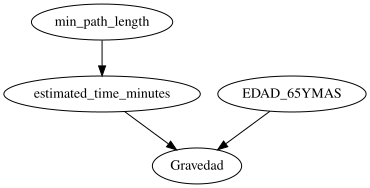

In [ ]:
from graphviz import Digraph

dot = Digraph()

dot.node("A", "min_path_length")
dot.node("B", "estimated_time_minutes")
dot.node("C", "Gravedad")
dot.node("D", "EDAD_65YMAS")

dot.edge("A", "B")
dot.edge("B", "C")
dot.edge("D", "C")

dot.render("bayes_net_problem2", format="png", cleanup=False)
dot

### Las comunas con más adultos mayores pueden tener mayor riesgo de gravedad en accidentes porque son más vulnerables (lo cual es cierto en la práctica).

In [ ]:
from pgmpy.models import DiscreteBayesianNetwork

# Estructura
edges = [
    ("estimated_time_minutes", "Gravedad"),
    ("min_path_length", "estimated_time_minutes"),
    ("EDAD_65YMAS", "Gravedad")
]

# Sin SMOTE
model_no_smote = DiscreteBayesianNetwork(edges)
model_no_smote.fit(df_bayes_no_smote_disc)

# Con SMOTE
model_smote = DiscreteBayesianNetwork(edges)
model_smote.fit(df_bayes_smote_disc)

# 🚦 8️⃣ Inferencia
infer_no_smote = VariableElimination(model_no_smote)
infer_smote = VariableElimination(model_smote)

# Ejemplo: probabilidad de Gravedad=1 cuando estimated_time_minutes = bin alto (3)
print("\n---- Inferencia SIN SMOTE ----")
q_no_smote = infer_no_smote.query(variables=["Gravedad"], evidence={"estimated_time_minutes": 3})
print(q_no_smote)

print("\n---- Inferencia CON SMOTE ----")
q_smote = infer_smote.query(variables=["Gravedad"], evidence={"estimated_time_minutes": 3})
print(q_smote)


---- Inferencia SIN SMOTE ----
+-------------+-----------------+
| Gravedad    |   phi(Gravedad) |
+=============+=================+
| Gravedad(0) |          0.8871 |
+-------------+-----------------+
| Gravedad(1) |          0.1129 |
+-------------+-----------------+

---- Inferencia CON SMOTE ----
+-------------+-----------------+
| Gravedad    |   phi(Gravedad) |
+=============+=================+
| Gravedad(0) |          0.5344 |
+-------------+-----------------+
| Gravedad(1) |          0.4656 |
+-------------+-----------------+


## Ahora haremos una tabla de inferencia multinivel para analizar varios tiempos y distancias:

In [ ]:
# Bins para recorrer
tiempos_bins = [0, 1, 2, 3]
dist_bins = [0, 1, 2, 3]

# Resultados
tabla_resultados = []

for t_bin in tiempos_bins:
    for d_bin in dist_bins:
        # SIN SMOTE
        q_no = infer_no_smote.query(variables=["Gravedad"], evidence={
            "estimated_time_minutes": t_bin,
            "min_path_length": d_bin
        })
        p_no = q_no.values[1]

        # CON SMOTE
        q_sm = infer_smote.query(variables=["Gravedad"], evidence={
            "estimated_time_minutes": t_bin,
            "min_path_length": d_bin
        })
        p_sm = q_sm.values[1]

        # Guardar fila
        tabla_resultados.append({
            "Tiempo_bin": t_bin,
            "Distancia_bin": d_bin,
            "P_Gravedad1_SIN_SMOTE": round(p_no, 4),
            "P_Gravedad1_CON_SMOTE": round(p_sm, 4)
        })

# Mostrar tabla
tabla_df = pd.DataFrame(tabla_resultados)
print("\n========== Tabla de Inferencia por niveles ==========")
print(tabla_df)



========== Tabla de Inferencia por niveles ==========
    Tiempo_bin  Distancia_bin  P_Gravedad1_SIN_SMOTE  P_Gravedad1_CON_SMOTE
0            0              0                 0.1210                 0.4824
1            0              1                 0.1210                 0.4824
2            0              2                 0.1210                 0.4824
3            0              3                 0.1210                 0.4824
4            1              0                 0.1305                 0.5248
5            1              1                 0.1305                 0.5248
6            1              2                 0.1305                 0.5248
7            1              3                 0.1305                 0.5248
8            2              0                 0.1223                 0.5008
9            2              1                 0.1223                 0.5008
10           2              2                 0.1223                 0.5008
11           2              3    

#HEATMAP

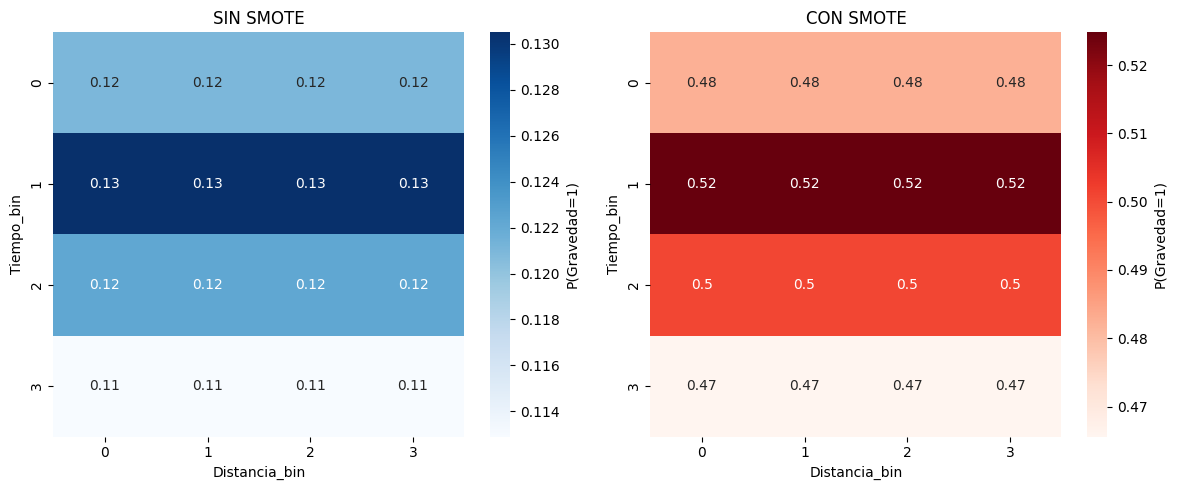

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Pivot para heatmap
pivot_smote = tabla_df.pivot(index="Tiempo_bin", columns="Distancia_bin", values="P_Gravedad1_CON_SMOTE")
pivot_no_smote = tabla_df.pivot(index="Tiempo_bin", columns="Distancia_bin", values="P_Gravedad1_SIN_SMOTE")

# Plot heatmaps
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.heatmap(pivot_no_smote, annot=True, cmap="Blues", cbar_kws={'label': 'P(Gravedad=1)'})
plt.title("SIN SMOTE")
plt.xlabel("Distancia_bin")
plt.ylabel("Tiempo_bin")

plt.subplot(1,2,2)
sns.heatmap(pivot_smote, annot=True, cmap="Reds", cbar_kws={'label': 'P(Gravedad=1)'})
plt.title("CON SMOTE")
plt.xlabel("Distancia_bin")
plt.ylabel("Tiempo_bin")

plt.tight_layout()
plt.show()

#CONCLUSIONES

- Existe relación positiva entre tiempo de traslado a urgencia y la probabilidad de gravedad: Accidentes con mayor estimated_time_minutes tienden a asociarse con mayor gravedad (fallecidos o heridos graves).
- La distancia mínima al hospital parece tener menor efecto que el tiempo (posiblemente porque tiempo ya captura congestión, calidad vial, etc.).
- El modelo entrenado con SMOTE permite identificar mejor esta relación, corrigiendo el sesgo del desbalance original.
- En comunas más alejadas de los principales centros hospitalarios (con mayores tiempos de traslado), se incrementa la gravedad de los siniestros viales. Esto sugiere que mejorar acceso rápido a servicios de urgencia puede reducir las consecuencias fatales.